In [1]:
import collections
import random
import re
import torch
from d2l import torch as d2l

In [4]:
class TimeMachine(d2l.DataModule):
    def _download(self):
        fname = d2l.download(d2l.DATA_URL + 'timemachine.txt', self.root,'090b5e7e70c295757f55df93cb0a180b9691891a')

        with open(fname) as f:
            return f.read()
        
    def _preprocess(self, text):
        return re.sub('[^A-Za-z]+', ' ', text).lower()

In [6]:
data = TimeMachine()
raw_text = data._download()
raw_text[:60]

'The Time Machine, by H. G. Wells [1898]\n\n\n\n\nI\n\n\nThe Time Tra'

In [7]:
text = data._preprocess(raw_text)
print(text[:60])

the time machine by h g wells i the time traveller for so it


### Tokenization
Tokens are atomic units of text. Each time step corresponds to 1 token. What precisely constitutes a token is a design choice.
For eg - For the text "**I am a student**", we can tokenize it into **["I", "am", "a", "student"]** (here each word is a token)or into represent the same sentence as a sequence of characters **["I", " ", "a", "m", " ", "a", " ", "s", "t", "u", "d", "e", "n", "t"]** (here each character is a token).

In [11]:
@d2l.add_to_class(TimeMachine) #@save
def _tokenize(self, text):
    """Tokenize text by characters"""
    return list(text)
tokens = data._tokenize(text)
','.join(tokens[:30])

't,h,e, ,t,i,m,e, ,m,a,c,h,i,n,e, ,b,y, ,h, ,g, ,w,e,l,l,s, '

In [14]:
class Vocab:
    """  
        Converts tokens to indices and vice versa.
        Unkown tokens are represented by '<unk>'
    """

    def __init__(self, tokens=[], min_freq=0, reserved_tokens=[]):
        # Flatten 2D list if required
        if tokens and isinstance(tokens[0], list):
            tokens = [token for line in tokens for token in line]
        #Count token frequencies
        counter = collections.Counter(tokens)
        self.token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)
        #List of unique tokens
        self.idx_to_token = list(sorted(set(
            ['<unk>'] + reserved_tokens + [token for token, freq in self.token_freqs if freq >= min_freq]
        )))
        self.token_to_idx = {token: idx for idx, token in enumerate(self.idx_to_token)}

    def __len__(self):
        return len(self.idx_to_token)
    
    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]
    
    def to_tokens(self, indices):
        if not isinstance(indices, (list, tuple)):
            return self.idx_to_token[indices]
        return [self.idx_to_token[index] for index in indices]
    
    @property
    def unk(self): 
        return self.token_to_idx['<unk>']

In [15]:
#Creating vocabulary for the Time Machine dataset
vocab = Vocab(tokens)
indices = vocab[tokens[:10]]
print('indices:', indices)
print('words:', vocab.to_tokens(indices))

indices: [21, 9, 6, 0, 21, 10, 14, 6, 0, 14]
words: ['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm']


In [16]:
@d2l.add_to_class(TimeMachine) #@save
def build(self, raw_text, vocab=None):
    tokens = self._tokenize(self._preprocess(raw_text))
    if vocab is None: vocab = Vocab(tokens)
    corpus = [vocab[token] for token in tokens]
    return corpus, vocab
corpus, vocab = data.build(raw_text)
len(corpus), len(vocab)

(173428, 28)

### Understanding Stop Words and Zipf's Law

## 1. Why Aren't the Most Frequent Words Very Useful?

If you count the words in a book, the most frequent words are usually things like:

| Rank | Word | Count |
| --- | --- | --- |
| 1 | the | 10,000 |
| 2 | of | 8,000 |
| 3 | and | 7,500 |
| 4 | to | 7,000 |
| 5 | a | 6,500 |

These words appear in almost every English text, regardless of the topic.

For example:

- A novel uses the word `the`.
- A science textbook uses the word `the`.
- A history book uses the word `the`.

Therefore, these words do not provide much information about what the document is actually about.

Such common grammatical words are called stop words.

### Examples of Stop Words

- Articles: the, a, an
- Pronouns: I, my, you
- Prepositions: of, to, in, on

Their primary purpose is to help form grammatically correct sentences rather than describe the document's content.

## 2. Why Were Stop Words Removed in Older NLP Systems?

Older NLP models often used the Bag-of-Words (BoW) representation.

### Example

Sentence:

text

```text
I love machine learning
```

Bag-of-Words Representation:

| Word | Count |
| --- | --- |
| I | 1 |
| love | 1 |
| machine | 1 |
| learning | 1 |

Bag-of-Words only counts word occurrences and ignores context and word order.

Since stop words appear frequently across almost all documents, they often contributed little useful information and increased computational cost.

As a result, many NLP pipelines removed them.

### Example

Original sentence:

text

```text
The cat sat on the mat
```

After removing stop words:

text

```text
cat sat mat
```

## 3. Why Don't Modern Models Remove Stop Words?

Modern neural architectures such as:

- RNNs (Recurrent Neural Networks)
- LSTMs (Long Short-Term Memory Networks)
- Transformers (BERT, GPT, etc.)

can understand context and word order.

Consider these two sentences:

Sentence 1:

text

```text
The dog bit the man
```

Sentence 2:

text

```text
The man bit the dog
```

Although they contain the same words, their meanings are very different.

Stop words help define sentence structure and relationships between words. Removing them may discard important contextual information.

Therefore, modern models typically keep stop words instead of filtering them out.

## 4. What Does "Word Frequency Decays Quickly" Mean?

Word frequencies drop rapidly as we move down the ranking.

### Example

| Rank | Word | Frequency |
| --- | --- | --- |
| 1 | the | 10,000 |
| 2 | of | 5,000 |
| 3 | and | 3,300 |
| 10 | is | 1,800 |
| 100 | river | 100 |
| 1000 | telescope | 5 |

Notice that:

- The most common word appears extremely often.
- Lower-ranked words appear much less frequently.
- Rare words dominate the vocabulary.

For example, the 10th most frequent word may occur less than one-fifth as often as the most frequent word.

## 5. What Is Zipf's Law?

Zipf's Law states:

> The frequency of a word is approximately inversely proportional to its rank.

### Mathematical Representation

$$
f(r) \propto \frac{1}{r}
$$

Where:

- $f(r)$ = Frequency of the word
- $r$ = Rank of the word

### Example

| Rank | Word | Frequency |
| --- | --- | --- |
| 1 | the | 10,000 |
| 2 | of | 5,000 |
| 3 | and | 3,300 |
| 10 | is | 1,000 |

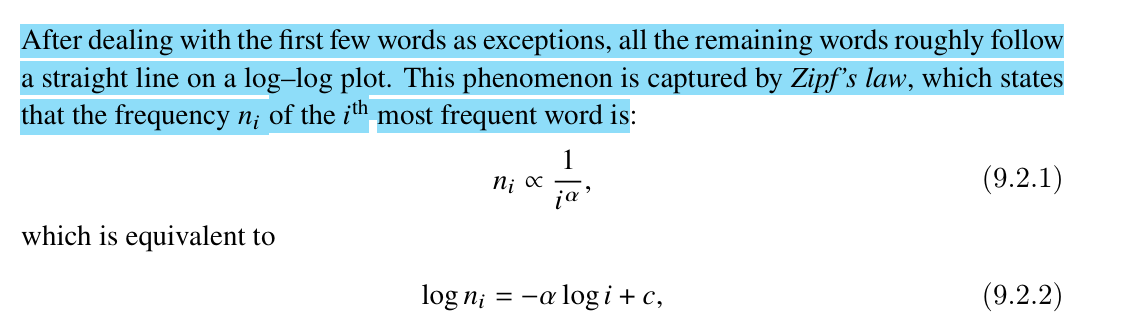

This means:

- Rank 2 words occur roughly half as often as rank 1 words.
- Rank 10 words occur roughly one-tenth as often as rank 1 words.

While not exact, real-world language data closely follows this pattern.

## 6. Why Is Zipf's Law Important?

Zipf's Law reveals that natural language contains two major types of words.

### A. A Few Extremely Common Words

Examples:

- the
- of
- to
- a
- and

### B. Many Extremely Rare Words

Examples:

- photosynthesis
- neuroplasticity
- blockchain

As a result:

1. Vocabulary sizes become very large.
2. Many words occur only a few times.
3. Rare-word handling becomes important.
4. Out-of-Vocabulary (OOV) problems arise.

This is one of the reasons modern Transformer models use subword tokenization, such as:

- BPE (Byte Pair Encoding)
- WordPiece
- SentencePiece

Subword tokenization helps models handle rare and previously unseen words by breaking them into smaller, reusable units.

## 7. Key Takeaways

- Stop words are common words such as `the`, `of`, and `to` that mostly serve grammatical functions.
- Older Bag-of-Words models often removed stop words because they added little descriptive information.
- Modern RNNs and Transformers retain stop words because they help capture context and sentence structure.
- Word frequencies decrease rapidly as rank increases.
- This pattern follows Zipf's Law, where:

$$
\boxed{\text{Frequency} \propto \frac{1}{\text{Rank}}}
$$

- Natural language consists of a small number of very frequent words and a very large number of rare words.
- Subword tokenization helps modern NLP models deal with rare words and OOV problems.

In [25]:
#Constructing vocabulary by words
words = text.split()
vocab = Vocab(words)
vocab.token_freqs[:10]

[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

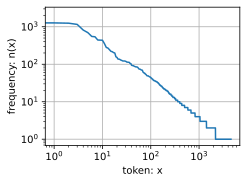

In [26]:
freqs = [freq for _, freq in vocab.token_freqs]
d2l.plot(freqs, xlabel='token: x', ylabel='frequency: n(x)', xscale='log', yscale='log')

In [28]:
bigram_tokens = ['--'.join(pair) for pair in zip(words[:-1], words[1:])]
bigram_vocab = Vocab(bigram_tokens)
bigram_vocab.token_freqs[:10]

[('of--the', 309),
 ('in--the', 169),
 ('i--had', 130),
 ('i--was', 112),
 ('and--the', 109),
 ('the--time', 102),
 ('it--was', 99),
 ('to--the', 85),
 ('as--i', 78),
 ('of--a', 73)]

In [29]:
trigram_tokens = ['--'.join(triple) for triple in zip(words[:-2], words[1:-1], words[2:])]
trigram_vocab = Vocab(trigram_tokens)
trigram_vocab.token_freqs[:10]

[('the--time--traveller', 59),
 ('the--time--machine', 30),
 ('the--medical--man', 24),
 ('it--seemed--to', 16),
 ('it--was--a', 15),
 ('here--and--there', 15),
 ('seemed--to--me', 14),
 ('i--did--not', 14),
 ('i--saw--the', 13),
 ('i--began--to', 13)]

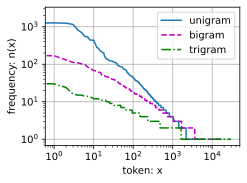

In [30]:
bigram_freqs = [freq for token, freq in bigram_vocab.token_freqs]
trigram_freqs = [freq for token, freq in trigram_vocab.token_freqs]
d2l.plot([freqs, bigram_freqs, trigram_freqs], xlabel='token: x',
            ylabel='frequency: n(x)', xscale='log', yscale='log',
            legend=['unigram', 'bigram', 'trigram'])